# 03 — Validation and Challenger

**Question for this notebook:** does the frozen champion scorecard still rank and price risk correctly on loans it has never seen (2014, out-of-time), and does a more complex model buy enough extra performance to justify itself?

The champion is loaded from disk exactly as saved in notebook 02 — nothing is refitted. The 2015 monitoring sample is not used here.

In [1]:
%load_ext autoreload
%autoreload 2

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit
from sklearn.metrics import brier_score_loss, roc_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
from src import validation as val
from src.challenger import fit_challenger
from src.data_prep import load_model_data, split_development
from src.features import CATEGORICAL, add_derived_features, candidate_features

pd.set_option("display.max_columns", 30)
TARGET = config.TARGET
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

data = add_derived_features(load_model_data())
train, valid = split_development(data)
oot = data[data["sample"] == "oot"]
samples = {"train": train, "validation": valid, "oot": oot}
y_oot = oot[TARGET].to_numpy()

with open(config.ROOT / "models" / "champion_scorecard.pkl", "rb") as f:
    card = pickle.load(f)
pd_champion = {name: card.predict_pd(df) for name, df in samples.items()}

(CVXPY) Oct 30 08:56:37 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/home/sava/project/.venv/lib/python3.12/site-packages/highspy/_core.cpython-312-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


## 1. Discrimination: does the model rank risky loans above safe ones?
Gini $= 2\cdot AUC - 1$ with a 95% bootstrap confidence interval (200 resamples), and the KS statistic (maximum gap between the score distributions of goods and bads).

In [2]:
def discrimination_row(y, score) -> dict:
    low, high = val.bootstrap_gini_ci(y, score)
    return {
        "loans": len(y),
        "bad_rate_pct": 100 * np.mean(y),
        "gini": val.gini(y, score),
        "gini_ci_low": low,
        "gini_ci_high": high,
        "ks": val.ks_statistic(y, score),
    }

discrimination = pd.DataFrame({
    name: discrimination_row(df[TARGET].to_numpy(), pd_champion[name]) for name, df in samples.items()
}).T
discrimination.round(4)

,loans,bad_rate_pct,gini,gini_ci_low,gini_ci_high,ks
train,80922.0,12.3934,0.3387,0.3286,0.3496,0.2460
validation,34681.0,12.3930,0.3258,0.3102,0.3441,0.2373
oot,162570.0,13.7264,0.3255,0.3181,0.3322,0.2326


## 2. Benchmark: Lending Club's own risk grade
LC's `sub_grade` (A1 = safest … G5 = riskiest) and `int_rate` are LC's own risk assessment, built on more information than this project has. They are used only as a yardstick, never as inputs.

In [3]:
def sub_grade_rank(s: pd.Series) -> np.ndarray:
    return ((s.str[0].map(ord) - ord("A")) * 5 + s.str[1].astype(int)).to_numpy()

benchmarks = {
    "champion scorecard": pd_champion["oot"],
    "LC sub_grade": sub_grade_rank(oot["sub_grade"]),
    "LC int_rate": oot["int_rate"].to_numpy(),
}
benchmark_table = pd.DataFrame({name: discrimination_row(y_oot, s) for name, s in benchmarks.items()}).T
benchmark_table.round(4)

,loans,bad_rate_pct,gini,gini_ci_low,gini_ci_high,ks
champion scorecard,162570.0,13.7264,0.3255,0.3181,0.3322,0.2326
LC sub_grade,162570.0,13.7264,0.3191,0.3119,0.3259,0.2365
LC int_rate,162570.0,13.7264,0.3154,0.3083,0.3225,0.2342


In [4]:
pd.Series(val.delong_test(y_oot, benchmarks["LC sub_grade"], pd_champion["oot"]), name="LC sub_grade vs champion (OOT)").round(4)

gini_a               0.3191
gini_b               0.3255
gini_diff           -0.0063
gini_diff_ci_low    -0.0134
gini_diff_ci_high    0.0007
z                   -1.7612
p_value              0.0782
Name: LC sub_grade vs champion (OOT), dtype: float64

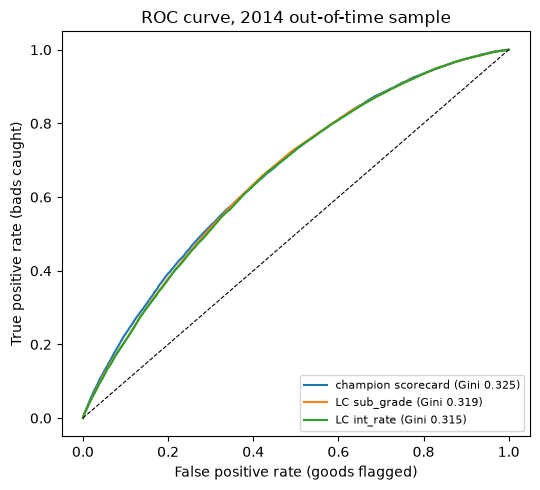

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, score in benchmarks.items():
    fpr, tpr, _ = roc_curve(y_oot, score)
    ax.plot(fpr, tpr, label=f"{name} (Gini {val.gini(y_oot, score):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="False positive rate (goods flagged)", ylabel="True positive rate (bads caught)", title="ROC curve, 2014 out-of-time sample")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_roc_oot.png", dpi=150)

## 3. Calibration: do predicted PDs match observed default rates?

**Calibration in the large** compares the portfolio-average PD with the observed default rate (ODR).
- *Binomial test* (one-sided): if the true PD equalled the prediction, how likely are this many defaults or more?
- *Jeffreys test* (as used in ECB validation reporting for internal models): p-value $= F_{Beta}(\overline{PD};\ D+0.5,\ N-D+0.5)$. A small p-value means the PD is significantly **under**estimated.
- *Brier score* and *Hosmer–Lemeshow* as secondary measures.

Note: all these tests assume defaults are independent. In reality defaults are correlated (shared economic conditions), so the p-values are optimistic: they flag deviations more readily than they should.

In [6]:
rows = {}
for name, df in samples.items():
    y, p = df[TARGET].to_numpy(), pd_champion[name]
    n, d = len(y), int(y.sum())
    rows[name] = {
        "loans": n, "defaults": d,
        "mean_pd_pct": 100 * p.mean(), "odr_pct": 100 * d / n,
        "binomial_p": val.binomial_pvalue(n, d, p.mean()),
        "jeffreys_p": val.jeffreys_pvalue(n, d, p.mean()),
        "brier": brier_score_loss(y, p),
        "hosmer_lemeshow_p": val.hosmer_lemeshow(y, p)["p_value"],
    }
calibration_large = pd.DataFrame(rows).T
calibration_large.round(4)

,loans,defaults,mean_pd_pct,odr_pct,binomial_p,jeffreys_p,brier,hosmer_lemeshow_p
train,80922.0,10029.0,12.3934,12.3934,0.5016,0.4995,0.1043,0.3687
validation,34681.0,4298.0,12.4333,12.3930,0.5925,0.5893,0.1045,0.5326
oot,162570.0,22315.0,13.0055,13.7264,0.0000,0.0000,0.1138,0.0000


**Calibration by risk grade.** Eight equal-population PD grades are fixed on the training sample (a simple master scale) and then applied unchanged to validation and OOT.

In [7]:
edges = val.grade_edges(pd_champion["train"], n_grades=8)
print("Grade PD boundaries (%):", np.round(100 * edges, 2))
calibration_by_grade = {
    name: val.calibration_table(samples[name][TARGET], pd_champion[name], val.assign_grades(pd_champion[name], edges))
    for name in ["validation", "oot"]
}
calibration_by_grade["oot"].round(4)

Grade PD boundaries (%): [  0.     5.26   7.41   9.31  11.27  13.5   16.2   20.29 100.  ]


,loans,defaults,mean_pd_pct,odr_pct,odr_ci_low_pct,odr_ci_high_pct,binomial_p,jeffreys_p
grade,,,,,,,,
1,18580,755,3.7730,4.0635,3.7890,4.3570,0.0207,0.0197
2,18948,1279,6.3658,6.7501,6.4015,7.1161,0.0163,0.0157
3,18624,1729,8.3654,9.2837,8.8753,9.7089,0.0000,0.0000
4,19630,2235,10.2811,11.3856,10.9488,11.8376,0.0000,0.0000
5,20077,2716,12.3594,13.5279,13.0618,14.0080,0.0000,0.0000
6,20512,3171,14.7971,15.4592,14.9710,15.9604,0.0041,0.0039
7,21873,4218,18.0728,19.2840,18.7666,19.8123,0.0000,0.0000
8,24326,6212,25.4458,25.5365,24.9924,26.0883,0.3751,0.3723


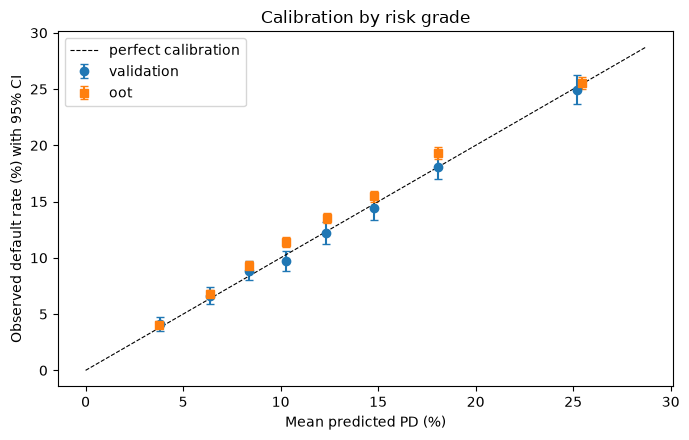

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, marker in [("validation", "o"), ("oot", "s")]:
    t = calibration_by_grade[name]
    ax.errorbar(
        t["mean_pd_pct"], t["odr_pct"],
        yerr=[t["odr_pct"] - t["odr_ci_low_pct"], t["odr_ci_high_pct"] - t["odr_pct"]],
        fmt=marker, capsize=3, label=name,
    )
lim = [0, 1.1 * calibration_by_grade["oot"]["odr_ci_high_pct"].max()]
ax.plot(lim, lim, "k--", lw=0.8, label="perfect calibration")
ax.set(xlabel="Mean predicted PD (%)", ylabel="Observed default rate (%) with 95% CI", title="Calibration by risk grade")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_calibration_by_grade.png", dpi=150)

## 4. Challenger: does a gradient-boosting model add enough?
Two LightGBM challengers: (a) the same 13 features as the scorecard (isolates the effect of the algorithm), (b) all 62 candidate features (algorithm + more information). Early stopping uses the validation sample, so their validation Gini is optimistic; the OOT sample is the fair comparison. The **DeLong test** compares two AUCs measured on the same loans.

In [11]:
all_features = candidate_features(data.columns.tolist())
challengers = {
    "LightGBM, scorecard features": fit_challenger(train, valid, card.features, CATEGORICAL, TARGET),
    "LightGBM, all candidates": fit_challenger(train, valid, all_features, CATEGORICAL, TARGET),
}
for name, ch in challengers.items():
    print(f"{name}: {len(ch.features)} features, {ch.model.best_iteration_} trees")

LightGBM, scorecard features: 13 features, 236 trees
LightGBM, all candidates: 62 features, 370 trees


In [12]:
rows = {"champion scorecard": {**discrimination_row(y_oot, pd_champion["oot"]), "mean_pd_pct": 100 * pd_champion["oot"].mean()}}
pd_challenger = {}
for name, ch in challengers.items():
    p = pd_challenger[name] = ch.predict_pd(oot)
    test = val.delong_test(y_oot, p, pd_champion["oot"])
    rows[name] = {
        **discrimination_row(y_oot, p),
        "mean_pd_pct": 100 * p.mean(),
        "gini_gain_vs_champion": test["gini_diff"],
        "gain_ci_low": test["gini_diff_ci_low"],
        "gain_ci_high": test["gini_diff_ci_high"],
        "delong_p": test["p_value"],
    }
comparison = pd.DataFrame(rows).T
comparison.round(4)

,loans,bad_rate_pct,gini,gini_ci_low,gini_ci_high,ks,mean_pd_pct,gini_gain_vs_champion,gain_ci_low,gain_ci_high,delong_p
champion scorecard,162570.0,13.7264,0.3255,0.3181,0.3322,0.2326,13.0055,NaN,NaN,NaN,NaN
"LightGBM, scorecard features",162570.0,13.7264,0.3358,0.3289,0.3430,0.2423,13.0994,0.0103,0.0073,0.0133,0.0
"LightGBM, all candidates",162570.0,13.7264,0.3638,0.3568,0.3716,0.2657,13.0521,0.0383,0.0339,0.0426,0.0


## 5. Explainability: do both models rely on the same drivers?
Mean absolute contribution to the log-odds of default on 5,000 OOT loans. For the challenger these are SHAP values (LightGBM's built-in `pred_contrib`); for the linear scorecard the exact equivalent is $\beta_j\,(WoE_j - \overline{WoE_j})$.

In [13]:
ch = challengers["LightGBM, scorecard features"]
explain_sample = oot.sample(5000, random_state=config.RANDOM_STATE)
X_explain = ch.frame(explain_sample)
shap_values = ch.model.booster_.predict(X_explain, pred_contrib=True)[:, :-1]

linear_contrib = (card.woe(explain_sample) - card.woe(train).mean()) * card.model.params[card.features]
importance = pd.DataFrame({
    "champion_mean_abs": linear_contrib.abs().mean(),
    "challenger_mean_abs_shap": pd.Series(np.abs(shap_values).mean(axis=0), index=ch.features),
})
importance["champion_rank"] = importance["champion_mean_abs"].rank(ascending=False).astype(int)
importance["challenger_rank"] = importance["challenger_mean_abs_shap"].rank(ascending=False).astype(int)
importance.sort_values("challenger_rank").round(4)

,champion_mean_abs,challenger_mean_abs_shap,champion_rank,challenger_rank
fico_mid,0.1717,0.2181,1,1
loan_to_income,0.1502,0.1464,2,2
dti,0.1126,0.1333,7,3
acc_open_past_24mths,0.1217,0.1330,4,4
annual_inc,0.0925,0.1214,9,5
tot_hi_cred_lim,0.1225,0.1184,3,6
bc_open_to_buy,0.1185,0.1101,5,7
mths_since_recent_inq,0.1181,0.1052,6,8
purpose,0.1032,0.0915,8,9
mths_since_recent_bc,0.0702,0.0650,11,10


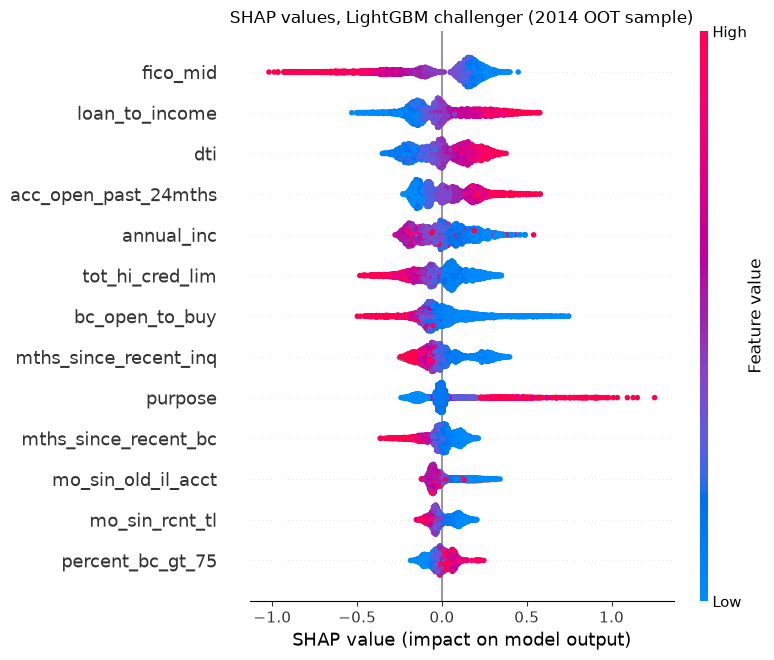

In [14]:
import shap

X_plot = X_explain.apply(lambda c: c.cat.codes if isinstance(c.dtype, pd.CategoricalDtype) else c)
shap.summary_plot(shap_values, X_plot, show=False, max_display=13)
plt.title("SHAP values, LightGBM challenger (2014 OOT sample)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_shap_challenger.png", dpi=150, bbox_inches="tight")

## 6. Recalibration (recommendation, not applied)
How large an intercept shift would make the champion's average PD equal the 2014 observed default rate? This keeps the ranking (Gini) unchanged and only moves the PD level. Whether it actually helps must be checked on data it was not fitted on (2015, Day 4).

In [15]:
log_odds_oot = card.log_odds_bad(oot)
intercept_shift = brentq(lambda s: expit(log_odds_oot + s).mean() - y_oot.mean(), -2, 2)
print(
    f"Intercept shift {intercept_shift:+.4f} moves the mean OOT PD from "
    f"{100 * expit(log_odds_oot).mean():.2f}% to {100 * y_oot.mean():.2f}% "
    f"(odds multiplied by {np.exp(intercept_shift):.3f})."
)

Intercept shift +0.0652 moves the mean OOT PD from 13.01% to 13.73% (odds multiplied by 1.067).


In [16]:
with open(config.ROOT / "models" / "challengers.pkl", "wb") as f:
    pickle.dump(challengers, f)
with open(config.ROOT / "models" / "validation_artifacts.pkl", "wb") as f:
    pickle.dump({"grade_edges": edges, "intercept_shift_2014": intercept_shift}, f)

discrimination.to_csv(config.REPORTS_DIR / "validation_discrimination.csv")
benchmark_table.to_csv(config.REPORTS_DIR / "validation_benchmark_oot.csv")
calibration_large.to_csv(config.REPORTS_DIR / "validation_calibration_in_the_large.csv")
calibration_by_grade["oot"].to_csv(config.REPORTS_DIR / "validation_calibration_by_grade_oot.csv")
comparison.to_csv(config.REPORTS_DIR / "validation_champion_vs_challenger_oot.csv")
importance.to_csv(config.REPORTS_DIR / "validation_feature_importance.csv")

## 7. Findings

**Verdict.** The scorecard ranks risk out of time as well as it did in development, but it **underestimates the level of risk** in 2014. Its ranking is statistically indistinguishable from Lending Club's own sub-grade. A gradient-boosting challenger ranks better (+3.8 Gini points with all features), most of which comes from *information the scorecard did not use*, not from the algorithm itself.

1. **Discrimination is stable over time.** Gini: train 0.339, validation 0.326, OOT 0.326 (95% CI 0.318–0.332); KS 0.233 OOT. No sign of decay one year after development.
2. **Benchmark.** On the same 2014 loans, LC's `sub_grade` reaches Gini 0.319 and `int_rate` 0.315. The DeLong test gives a difference of −0.6 Gini points (95% CI −1.3 to +0.1, p = 0.08): **equivalent, not better**. A 13-feature, fully explainable scorecard built without LC's internal information matches LC's own grading.
3. **Calibration fails out of time.** The mean predicted PD rose from 12.4% to 13.0% (the 2014 population *looks* riskier on its features), but the observed default rate rose further, to 13.7%. The binomial and Jeffreys tests reject "PD is not underestimated" for the portfolio (p < 0.001) and per grade at p < 0.05 in 7 of 8 grades (p < 0.001 in 4 of them); the gap is 0.3–1.2 percentage points in grades 1–7. Only the riskiest grade (25.4% predicted vs 25.5% observed) is in line. In development (train and validation) calibration was accurate (Jeffreys p ≈ 0.5).
4. **Interpretation.** Of the +1.3 pp rise in default rate from development to OOT, about +0.6 pp is explained by a riskier mix of borrowers (captured by the model) and about +0.7 pp is not — consistent with a change in the environment or in LC's lending policy rather than a broken model. This is exactly the pattern that monitoring should detect and investigate.
5. **Caveat on the tests.** With 162,570 loans these tests have enormous power, and they assume independent defaults; real defaults are correlated, so the p-values overstate the evidence. The *size* of the gap (≈5% relative underestimation) matters more than the p-value.
6. **Challenger.** Same 13 features: +1.0 Gini point (CI +0.7 to +1.3); all 62 candidates: +3.8 points (CI +3.4 to +4.3); both significant (DeLong p < 0.001). Decomposition: ~1 point from the algorithm (non-linearities/interactions), ~2.8 points from extra information.
7. **Explainability.** SHAP values for the challenger and the exact linear contributions of the scorecard agree on the two strongest drivers (FICO, loan-to-income) and on the direction of every feature; the middle ranks differ slightly (e.g. DTI 3rd vs 7th).
8. **Recalibration (recommendation only).** An intercept shift of +0.065 (odds × 1.067) would align the mean PD with 2014 experience without changing the ranking. Whether this helps must be checked on 2015 data (Day 4), because fitting and testing it on 2014 would be circular.

**Recommendation.** Keep the scorecard as the champion: it is stable, transparent, matches the LC benchmark, and its weakness is the PD *level*, which can be fixed with a documented recalibration. Record the challenger's +3.8 Gini points as evidence that the next development cycle should revisit the features the scorecard excluded (the IV < 0.02 threshold and the correlation rule), rather than switch to a less transparent model now.